C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


Using device: cuda


C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\huggingface_hub\file_download.py:797: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss
1,0.067500,0.099607
2,0.045100,0.069536
3,0.000100,0.074868


Evaluation Results: {'eval_loss': 0.07486766576766968, 'eval_runtime': 202.8972, 'eval_samples_per_second': 7.886, 'eval_steps_per_second': 0.986, 'epoch': 3.0}

📊 Classification Report:
               precision    recall  f1-score   support

         Low       0.97      0.99      0.98       876
     Neutral       0.99      0.98      0.99       666
        High       0.90      0.66      0.76        58

    accuracy                           0.98      1600
   macro avg       0.96      0.88      0.91      1600
weighted avg       0.98      0.98      0.98      1600



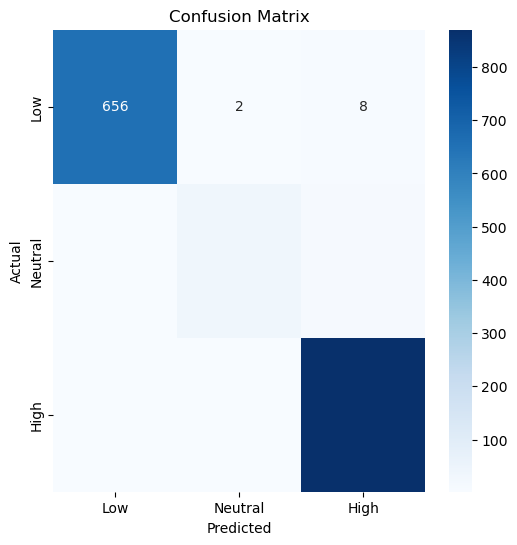

ValueError: x and y must have same first dimension, but have shapes (480,) and (4,)

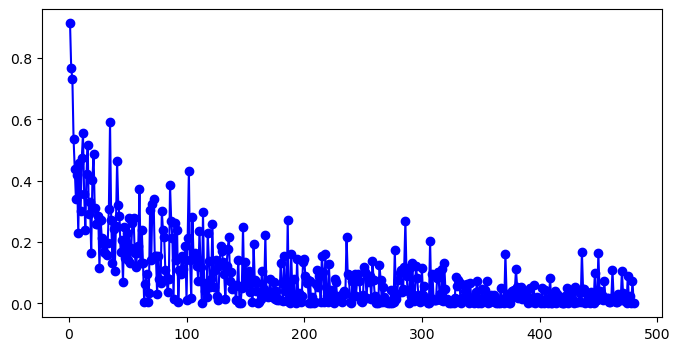

In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# 🚀 CHECK FOR CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 🔹 Load the dataset
df = pd.read_csv("data/train.csv")  # Adjust path if needed

# 🔹 Map emotions to stress levels (as class names)
emotion_to_stress = {
    0: "High",    # Sadness → High Stress
    1: "Low",     # Joy → Low Stress
    2: "Low",     # Love → Low Stress
    3: "High",    # Anger → High Stress
    4: "High",    # Fear → High Stress
    5: "Neutral"  # Surprise → Neutral Stress
}

df["label"] = df["label"].map(emotion_to_stress)

# 🚀 Train-Test Split (80% Train, 10% Validation, 10% Test)
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df["text"], df["label"], test_size=0.2, stratify=df["label"], random_state=42
)
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

# 🔹 Convert labels to integer encoding
label_to_int = {"Low": 0, "Neutral": 1, "High": 2}
train_labels = train_labels.map(label_to_int)
val_labels = val_labels.map(label_to_int)
test_labels = test_labels.map(label_to_int)

# 🔹 Load tokenizer
MODEL_NAME = "distilbert-base-uncased"
tokenizer = DistilBertTokenizer.from_pretrained(MODEL_NAME)

# 🔹 Tokenization function
def tokenize_function(texts):
    return tokenizer(list(texts), padding="max_length", truncation=True, return_tensors="pt")

# 🔹 Convert to Hugging Face Dataset format
train_encodings = tokenize_function(train_texts)
val_encodings = tokenize_function(val_texts)
test_encodings = tokenize_function(test_texts)

train_dataset = Dataset.from_dict({"input_ids": train_encodings["input_ids"], "attention_mask": train_encodings["attention_mask"], "labels": list(train_labels)})
val_dataset = Dataset.from_dict({"input_ids": val_encodings["input_ids"], "attention_mask": val_encodings["attention_mask"], "labels": list(val_labels)})
test_dataset = Dataset.from_dict({"input_ids": test_encodings["input_ids"], "attention_mask": test_encodings["attention_mask"], "labels": list(test_labels)})

# 🔹 Load pre-trained DistilBERT model for classification
model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)
model.to(device)

# 🔹 Training arguments
training_args = TrainingArguments(
    output_dir="./results",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    logging_dir="./logs",
    logging_steps=10,
    learning_rate=5e-5,
    fp16=torch.cuda.is_available(),
)

# 🔹 Trainer object
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
)

# 🚀 Train the model
trainer.train()

# 🚀 Save model
model.save_pretrained("./trained_model")
tokenizer.save_pretrained("./trained_model")

# 🚀 Evaluate the model
eval_results = trainer.evaluate()
print(f"Evaluation Results: {eval_results}")

# 🔹 Predictions on test data
preds = trainer.predict(test_dataset)
y_true = np.array(test_labels)
y_pred = np.argmax(preds.predictions, axis=1)

# 🔹 Convert back to class names
int_to_label = {0: "Low", 1: "Neutral", 2: "High"}
y_true = [int_to_label[label] for label in y_true]
y_pred = [int_to_label[label] for label in y_pred]

# 🔹 Classification Report
print("\n📊 Classification Report:\n", classification_report(y_true, y_pred, target_names=["Low", "Neutral", "High"]))

# 🔹 Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=["Low", "Neutral", "High"])
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Low", "Neutral", "High"], yticklabels=["Low", "Neutral", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 🔹 Plot Loss & Accuracy
logs = trainer.state.log_history
train_losses = [log["loss"] for log in logs if "loss" in log]
eval_losses = [log["eval_loss"] for log in logs if "eval_loss" in log]
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_losses, "b-o", label="Training Loss")
plt.plot(epochs, eval_losses, "r-o", label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.show()

# 🚀 Test on new samples
def predict(text):
    inputs = tokenizer(text, return_tensors="pt", padding="max_length", truncation=True).to(device)
    with torch.no_grad():
        logits = model(**inputs).logits
    predicted_class = torch.argmax(logits, dim=1).item()
    return int_to_label[predicted_class]

# 🔹 Example Prediction
example_text = "I am feeling very stressed today"
print(f"Predicted Stress Level: {predict(example_text)}")
